# Travel Reimbursement Approval Agent
**GenAI Developer Assignment** · Gayatri Vidhate

An agent that reviews a travel claim against policy (POL-*), calls tools (policy lookup, receipt / per-diem / airfare / timeliness / tier / duplicate / consistency checks), and returns a structured decision: `APPROVE`, `PARTIAL_APPROVE`, `REJECT` or `MANUAL_REVIEW`.

## README
**Setup**
1. Python 3.9+ and Jupyter (`pip install notebook`).
2. *(Optional, enables real LLM tool-calling)* get a free key at https://console.groq.com and set:
   - `GROQ_API_KEY` (required only for LLM mode)
   - `GROQ_MODEL` (optional, default `llama-3.3-70b-versatile`)
3. No key? The notebook still runs end-to-end in **offline mode** (same tools, scripted planner, template explanations).

**Run**
- `jupyter notebook GayatriVidhate.ipynb` → *Kernel → Restart & Run All*. No manual steps.
- Dashboard image is auto-saved as `UI SS_1.png` next to the notebook.
- The **last code cell** prints the final JSON array (5 claims).

**Architecture (one line)**: `claim JSON → policy retrieval → LLM picks tools (or scripted planner) → tool facts → rule engine decides → validator → JSON`.
The LLM *plans and explains*; money and decisions come from deterministic code, so the output is reliable.

In [1]:
%pip install -q pandas matplotlib groq ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.9 MB/s eta 0:00:00


In [2]:
"""Imports and global configuration. The LLM (Groq) is optional; no key -> offline mode."""
import os, re, json
from datetime import date
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

GROQ_API_KEY = os.getenv("GROQ_API_KEY", "")
GROQ_MODEL = os.getenv("GROQ_MODEL", "llama-3.3-70b-versatile")
USE_LLM = bool(GROQ_API_KEY)
client = None
if USE_LLM:
    try:
        from groq import Groq
        client = Groq(api_key=GROQ_API_KEY)
    except Exception as exc:                      # missing package / bad key format
        print("Groq unavailable, falling back to offline mode:", exc)
        USE_LLM = False
print("Mode:", "LLM tool-calling (Groq)" if USE_LLM else "Offline scripted planner (no API key)")

Mode: Offline scripted planner (no API key)


## 1. Policy & limits (Appendix A)
Policy is stored as data (id → text + search tags) so it can be **retrieved** and **cited**. Limits are constants used by the tools.

In [3]:
"""Policy knowledge base, limit tables and a tiny keyword retriever (context grounding)."""
POLICY = {
    "POL-CAT-01": {"text": "Eligible with a business purpose: airfare (economy only), lodging, meals (per-diem), ground transport (taxi, rideshare, train, rental car, parking), conference/registration fees.",
                   "tags": "eligible categories airfare lodging meals ground transport taxi rideshare train rental parking conference registration fees"},
    "POL-CAT-02": {"text": "Never reimbursable, deducted in full: alcohol, minibar, spa, gym, personal entertainment, in-room movies, personal shopping, gifts, traffic fines, penalties, late fees, any personal expense.",
                   "tags": "ineligible alcohol minibar spa gym entertainment movies shopping gifts fines penalties late personal reject"},
    "POL-PD-01": {"text": "Meals: maximum $75 per day. Excess over the daily cap is deducted.", "tags": "meals meal food dinner lunch breakfast per diem daily cap"},
    "POL-PD-02": {"text": "Lodging: maximum $200 per night. Excess over the nightly cap is deducted.", "tags": "lodging hotel room night nightly cap per diem"},
    "POL-PD-03": {"text": "Ground transport: maximum $50 per day. Excess is deducted.", "tags": "ground transport taxi rideshare train rental parking daily cap"},
    "POL-AIR-01": {"text": "Only economy airfare is reimbursable. Business/first class is a policy exception: route to MANUAL_REVIEW (pre-approval may exist), do not auto-deduct.",
                   "tags": "airfare flight class economy business first exception pre-approval manual review"},
    "POL-RCT-01": {"text": "Any single line item above $25 needs an itemized receipt. Airfare and lodging always need a receipt.", "tags": "receipt itemized required above 25 airfare lodging"},
    "POL-RCT-02": {"text": "Missing required receipt: do not silently reject; route to MANUAL_REVIEW so the reviewer can request it.", "tags": "missing receipt manual review request"},
    "POL-APR-01": {"text": "Reimbursable total <= $500: may be auto-approved if fully compliant.", "tags": "approval threshold auto approve total 500"},
    "POL-APR-02": {"text": "Reimbursable total > $500 and <= $2,000: approvable when fully compliant (manager tier).", "tags": "approval threshold manager tier total 2000"},
    "POL-APR-03": {"text": "Reimbursable total > $2,000 exceeds agent authority: MANUAL_REVIEW (director approval).", "tags": "approval threshold director high value total above 2000 manual review"},
    "POL-TIME-01": {"text": "Claims must be submitted within 30 days of the expense date; late claims go to MANUAL_REVIEW.", "tags": "timeliness submission window 30 days late"},
}

ELIGIBLE = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE = {"spa", "minibar", "alcohol", "gym", "entertainment", "movies", "shopping", "gifts", "fines", "penalties", "late_fees", "personal"}
PER_UNIT_CAPS = {"meals": (75, "POL-PD-01", "day"), "lodging": (200, "POL-PD-02", "night"), "ground_transport": (50, "POL-PD-03", "day")}
RECEIPT_THRESHOLD, ALWAYS_RECEIPT = 25, {"airfare", "lodging"}
AUTO_MAX, MANAGER_MAX, LATE_DAYS = 500, 2000, 30
STOP = {"the", "a", "an", "of", "for", "and", "or", "to", "in", "is", "on", "with", "per", "any", "all"}


def _words(text):
    """Lower-case word set of `text` without stopwords."""
    return set(re.findall(r"[a-z0-9]+", text.lower())) - STOP


def retrieve_policy(query, top_k=4):
    """Return the `top_k` policy rules most relevant to `query` (keyword-overlap score)."""
    q = _words(query)
    scored = sorted(((len(q & _words(r["text"] + " " + r["tags"])), pid) for pid, r in POLICY.items()), reverse=True)
    return [{"id": pid, "text": POLICY[pid]["text"]} for score, pid in scored[:top_k] if score > 0]

## 2. Claim intake (Appendix B)
The five provided claims, encoded as JSON exactly as given. Two helper fields are taken straight from the descriptions: `units` (nights/days, e.g. "2 nights", "3 days") and `attendees` (e.g. "dinner for 4"). `total_claimed` is the declared total, used for a consistency check.

In [4]:
"""The 5 provided sample claims (Appendix B) as JSON-style dicts, plus an intake normaliser."""
def item(category, description, amount, receipt, units=1, attendees=1):
    """Build one claim line item."""
    return {"category": category, "description": description, "amount": float(amount),
            "receipt": receipt, "units": units, "attendees": attendees}

CLAIM_LIST = [
    {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
     "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20", "total_claimed": 1110.00,
     "items": [item("airfare", "Round-trip economy airfare", 420, True),
               item("lodging", "Hotel, 2 nights @ $180", 360, True, units=2),
               item("meals", "Meals, 3 days @ ~$60/day", 180, True, units=3),
               item("conference_fees", "Conference registration", 150, True)]},
    {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
     "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25", "total_claimed": 380.00,
     "items": [item("spa", "Hotel spa package", 300, True), item("minibar", "In-room minibar", 80, True)]},
    {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
     "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22", "total_claimed": 940.00,
     "items": [item("airfare", "Round-trip economy airfare", 300, True),
               item("lodging", "Hotel, 2 nights @ $250", 500, True, units=2),
               item("meals", "Meals, 2 days @ $70/day", 140, True, units=2)]},
    {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
     "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28", "total_claimed": 3000.00,
     "items": [item("airfare", "Business-class international airfare", 2400, True),
               item("lodging", "Hotel, 3 nights", 600, False, units=3)]},
    {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
     "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24", "total_claimed": 220.00,
     "items": [item("meals", "Client dinner for 4 (business development)", 220, False, units=1, attendees=4)]},
]
CLAIMS = {c["claim_id"]: c for c in CLAIM_LIST}      # tools look claims up here
SAMPLE_IDS = [c["claim_id"] for c in CLAIM_LIST]
HISTORY = []                                          # previously paid claims (for duplicate detection)

pd.DataFrame([{"claim_id": c["claim_id"], "employee": c["employee"], "items": len(c["items"]), "claimed": c["total_claimed"]} for c in CLAIM_LIST])

,claim_id,employee,items,claimed
0,CLM-001,A. Rivera,4,1110.0
1,CLM-002,B. Osei,2,380.0
2,CLM-003,C. Nakamura,3,940.0
3,CLM-004,D. Fischer,2,3000.0
4,CLM-005,E. Haddad,1,220.0


## 3. Tools
Each tool is a small pure function that returns JSON-serialisable facts and the `policy_refs` it relied on. The LLM calls them by name; the harness guarantees the mandatory ones always run.

| Tool | Purpose |
|---|---|
| `lookup_policy` | retrieve policy rules (grounding) |
| `check_consistency` | declared total, dates, purpose, group meals (conflicts / ambiguity) |
| `check_eligibility` | eligible vs ineligible vs unknown categories |
| `check_receipts` | POL-RCT-01/02 receipt rules |
| `check_per_diem` | meal / lodging / ground caps |
| `check_airfare_class` | business / first class exception |
| `check_timeliness` | 30-day window |
| `check_approval_tier` | total after deductions → auto / manager / director |
| `detect_duplicates` | same employee + trip + amount |
| `validate_output` | schema + sanity guard on the final object |

In [5]:
"""Tool functions. Each takes a claim_id (except lookup_policy) and returns a dict of facts."""
def r2(x):
    """Round to 2 decimals (money)."""
    return round(float(x) + 1e-9, 2)


def _split(claim):
    """Return index lists (eligible, ineligible, unknown) for a claim's items."""
    el, inel, unk = [], [], []
    for i, it in enumerate(claim["items"]):
        c = it["category"].lower().strip()
        (el if c in ELIGIBLE else inel if c in INELIGIBLE else unk).append(i)
    return el, inel, unk


def tool_lookup_policy(query):
    """Retrieve the most relevant policy rules for a free-text query."""
    return {"rules": retrieve_policy(query, top_k=4)}


def tool_check_consistency(claim_id):
    """Detect conflicting/ambiguous info: total mismatch, bad dates, no purpose, invalid amounts, group meals."""
    c, issues = CLAIMS[claim_id], []
    total = sum(i["amount"] for i in c["items"])
    if "total_claimed" in c and abs(c["total_claimed"] - total) > 0.01:
        issues.append(f"declared total {c['total_claimed']} != sum of items {r2(total)}")
    if not c.get("purpose"):
        issues.append("missing business purpose")
    ts, te, sub = (date.fromisoformat(c[k]) for k in ("trip_start", "trip_end", "submitted"))
    if te < ts:
        issues.append("trip_end is before trip_start")
    if sub < ts:
        issues.append("claim submitted before the trip started")
    for it in c["items"]:
        if it["amount"] <= 0 or it.get("units", 1) < 1:
            issues.append(f"invalid amount/units on {it['category']}")
        if it["category"] == "meals" and it.get("attendees", 1) > 1:
            issues.append(f"group meal for {it['attendees']} people: per-diem basis (per person vs per claim) is not defined in policy")
    return {"issues": issues, "ambiguous": bool(issues), "policy_refs": []}


def tool_check_eligibility(claim_id):
    """Split items into eligible / ineligible (POL-CAT-02) / unknown categories."""
    c = CLAIMS[claim_id]
    el, inel, unk = _split(c)
    refs = (["POL-CAT-01"] if el else []) + (["POL-CAT-02"] if inel else [])
    return {"eligible": [c["items"][i]["category"] for i in el],
            "ineligible": [{"category": c["items"][i]["category"], "amount": c["items"][i]["amount"]} for i in inel],
            "unknown": [c["items"][i]["category"] for i in unk],
            "ineligible_total": r2(sum(c["items"][i]["amount"] for i in inel)), "policy_refs": refs}


def tool_check_receipts(claim_id):
    """List eligible items that need a receipt (POL-RCT-01) but have none (POL-RCT-02)."""
    c = CLAIMS[claim_id]
    el, _, _ = _split(c)
    missing = []
    for i in el:
        it = c["items"][i]
        need = it["amount"] > RECEIPT_THRESHOLD or it["category"] in ALWAYS_RECEIPT
        if need and not it.get("receipt"):
            missing.append({"category": it["category"], "amount": it["amount"],
                            "doc": f"Itemized {it['category']} receipt (${it['amount']:.2f})"})
    return {"missing": missing, "policy_refs": ["POL-RCT-01", "POL-RCT-02"] if missing else []}


def tool_check_per_diem(claim_id):
    """Apply per-unit caps (meals $75/day, lodging $200/night, ground $50/day) and compute the excess."""
    c = CLAIMS[claim_id]
    el, _, _ = _split(c)
    rows = []
    for i in el:
        it = c["items"][i]
        if it["category"] in PER_UNIT_CAPS:
            rate, ref, unit = PER_UNIT_CAPS[it["category"]]
            cap = rate * it.get("units", 1)
            allowed = min(it["amount"], cap)
            rows.append({"category": it["category"], "claimed": it["amount"], "units": it.get("units", 1), "unit": unit,
                         "cap": cap, "allowed": r2(allowed), "excess": r2(it["amount"] - allowed), "ref": ref})
    return {"rows": rows, "total_excess": r2(sum(r["excess"] for r in rows)), "policy_refs": sorted({r["ref"] for r in rows})}


def tool_check_airfare_class(claim_id):
    """Flag business/first-class airfare (POL-AIR-01 exception -> manual review, never auto-deduct)."""
    c = CLAIMS[claim_id]
    air = [i for i in c["items"] if i["category"] == "airfare"]
    premium = [{"description": i["description"], "amount": i["amount"]} for i in air if re.search(r"\b(business|first)\b", i["description"], re.I)]
    return {"premium": premium, "policy_refs": ["POL-AIR-01"] if air else []}


def tool_check_timeliness(claim_id):
    """Check the 30-day submission window (POL-TIME-01), measured from trip end."""
    c = CLAIMS[claim_id]
    days = (date.fromisoformat(c["submitted"]) - date.fromisoformat(c["trip_end"])).days
    return {"days_since_expense": days, "late": days > LATE_DAYS, "policy_refs": ["POL-TIME-01"] if days > LATE_DAYS else []}


def reimbursable_total(claim_id):
    """Eligible amount minus per-diem excess (the base for approval tiers)."""
    c = CLAIMS[claim_id]
    el, _, _ = _split(c)
    return r2(sum(c["items"][i]["amount"] for i in el) - tool_check_per_diem(claim_id)["total_excess"])


def tool_check_approval_tier(claim_id):
    """Map the reimbursable total to POL-APR-01/02/03."""
    t = reimbursable_total(claim_id)
    tier, ref = ("AUTO", "POL-APR-01") if t <= AUTO_MAX else ("MANAGER", "POL-APR-02") if t <= MANAGER_MAX else ("DIRECTOR", "POL-APR-03")
    return {"reimbursable_total": t, "tier": tier, "policy_refs": [ref] if t > 0 else []}


def tool_detect_duplicates(claim_id):
    """Find other/past claims with the same employee, trip dates and total, plus repeated lines inside the claim."""
    c = CLAIMS[claim_id]
    sig = lambda x: (x["employee"], x["trip_start"], x["trip_end"], r2(sum(i["amount"] for i in x["items"])))
    dups = [o["claim_id"] for o in list(CLAIMS.values()) + HISTORY if o["claim_id"] != claim_id and sig(o) == sig(c)]
    lines = [(i["category"], i["amount"], i["description"]) for i in c["items"]]
    repeated = len(lines) != len(set(lines))
    return {"duplicates": dups, "repeated_lines": repeated, "policy_refs": []}


TOOL_FUNCS = {"lookup_policy": tool_lookup_policy, "check_consistency": tool_check_consistency,
              "check_eligibility": tool_check_eligibility, "check_receipts": tool_check_receipts,
              "check_per_diem": tool_check_per_diem, "check_airfare_class": tool_check_airfare_class,
              "check_timeliness": tool_check_timeliness, "check_approval_tier": tool_check_approval_tier,
              "detect_duplicates": tool_detect_duplicates}
REQUIRED_TOOLS = [n for n in TOOL_FUNCS if n != "lookup_policy"]

TOOL_DESCRIPTIONS = {
    "lookup_policy": "Search the travel policy; returns the most relevant POL-* rules for a query.",
    "check_consistency": "Find conflicting or ambiguous information in the claim (totals, dates, group meals).",
    "check_eligibility": "Classify each line item as eligible / ineligible / unknown category.",
    "check_receipts": "Find items that require a receipt but have none.",
    "check_per_diem": "Apply meal/lodging/ground-transport caps and compute excess.",
    "check_airfare_class": "Detect business/first-class airfare (policy exception).",
    "check_timeliness": "Check the 30-day submission window.",
    "check_approval_tier": "Compute reimbursable total after deductions and the approval tier.",
    "detect_duplicates": "Detect duplicate claims or repeated line items.",
}
TOOL_SPECS = [{"type": "function", "function": {
    "name": n, "description": TOOL_DESCRIPTIONS[n],
    "parameters": {"type": "object",
                   "properties": ({"query": {"type": "string"}} if n == "lookup_policy" else {"claim_id": {"type": "string"}}),
                   "required": ["query"] if n == "lookup_policy" else ["claim_id"]}}} for n in TOOL_FUNCS]

FIELDS = {"claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs", "policy_refs", "confidence", "explanation", "tools_used"}
DECISIONS = {"APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"}


def validate_output(result, claimed_total):
    """Schema + sanity guard. Returns a list of error strings (empty list = valid)."""
    errs = []
    if set(result) != FIELDS:
        errs.append(f"fields mismatch: {sorted(set(result) ^ FIELDS)}")
        return errs
    if result["decision"] not in DECISIONS:
        errs.append("invalid decision")
    for k in ("approved_amount", "deducted_amount"):
        if not isinstance(result[k], (int, float)) or result[k] < 0:
            errs.append(f"{k} must be a non-negative number")
    if not errs and result["approved_amount"] + result["deducted_amount"] > claimed_total + 0.01:
        errs.append("approved + deducted exceeds claimed total")
    if not (isinstance(result["confidence"], (int, float)) and 0 <= result["confidence"] <= 1):
        errs.append("confidence must be within 0..1")
    if not isinstance(result["missing_docs"], list) or not isinstance(result["tools_used"], list) or len(result["tools_used"]) < 2:
        errs.append("missing_docs/tools_used must be lists (>= 2 tools)")
    if any(r not in POLICY for r in result["policy_refs"]):
        errs.append("unknown policy ref")
    if result["decision"] == "APPROVE" and (result["missing_docs"] or result["deducted_amount"]):
        errs.append("APPROVE cannot have missing docs or deductions")
    if result["decision"] == "REJECT" and result["approved_amount"] != 0:
        errs.append("REJECT must have approved_amount 0")
    if result["decision"] == "PARTIAL_APPROVE" and result["deducted_amount"] <= 0:
        errs.append("PARTIAL_APPROVE needs a deduction")
    if not str(result["explanation"]).strip():
        errs.append("empty explanation")
    return errs

print("Tools ready:", ", ".join(TOOL_FUNCS), "+ validate_output")

Tools ready: lookup_policy, check_consistency, check_eligibility, check_receipts, check_per_diem, check_airfare_class, check_timeliness, check_approval_tier, detect_duplicates + validate_output


## 4. Agent workflow
1. **Ground**: retrieve policy rules relevant to the claim's categories (`lookup_policy`) and put them in the prompt.
2. **Plan + act**: the LLM decides which tools to call (Groq function-calling loop, max 10 steps). Offline mode runs the same tools with a scripted planner.
3. **Guarantee**: any mandatory tool the LLM skipped is executed by the harness and logged as `harness-forced`.
4. **Decide**: a deterministic rule engine combines tool facts into decision + amounts (`MANUAL_REVIEW` is preferred whenever anything is uncertain). If the LLM's proposed decision differs, the rules win and confidence is lowered.
5. **Validate**: `validate_output`; on failure the claim falls back to `MANUAL_REVIEW`.

In [6]:
"""Rule engine: combines tool facts into decision, amounts, refs, missing docs, confidence and explanation."""
def decide(claim, f):
    """Return the result dict (without tools_used) and the list of manual-review reasons."""
    el, rc, pdm, air = f["check_eligibility"], f["check_receipts"], f["check_per_diem"], f["check_airfare_class"]
    tm, tier, dup, con = f["check_timeliness"], f["check_approval_tier"], f["detect_duplicates"], f["check_consistency"]
    claimed = r2(sum(i["amount"] for i in claim["items"]))
    hard, soft = [], []                       # hard = policy-mandated routing, soft = ambiguity
    if not claim["items"]:
        hard.append("claim has no line items")
    if el["unknown"]:
        soft.append(f"unclassified categories: {', '.join(el['unknown'])}")
    if rc["missing"]:
        hard.append("missing required receipt (POL-RCT-02): " + ", ".join(m["category"] for m in rc["missing"]))
    if air["premium"]:
        hard.append("business/first-class airfare is a policy exception (POL-AIR-01), pre-approval must be verified")
    if tm["late"]:
        hard.append(f"submitted {tm['days_since_expense']} days after expense (> {LATE_DAYS}, POL-TIME-01)")
    if tier["tier"] == "DIRECTOR":
        hard.append(f"reimbursable total ${tier['reimbursable_total']:.2f} exceeds $2,000 agent authority (POL-APR-03)")
    if dup["duplicates"] or dup["repeated_lines"]:
        soft.append("possible duplicate claim or repeated line item")
    soft += con["issues"]

    nothing_reimbursable = bool(claim["items"]) and not el["eligible"] and not el["unknown"]
    if not claim["items"]:
        decision = "MANUAL_REVIEW"
    elif nothing_reimbursable:
        decision = "REJECT"
    elif hard or soft:
        decision = "MANUAL_REVIEW"
    elif el["ineligible_total"] + pdm["total_excess"] > 0:
        decision = "PARTIAL_APPROVE"
    else:
        decision = "APPROVE"

    reimb = tier["reimbursable_total"]
    if decision in ("APPROVE", "PARTIAL_APPROVE"):
        approved, deducted = reimb, r2(claimed - reimb)
    elif decision == "REJECT":
        approved, deducted = 0.0, claimed
    else:                                      # nothing is paid out; only definite POL-CAT-02 deductions are stated
        approved, deducted = 0.0, el["ineligible_total"]

    refs = set()
    for k in (el, rc, pdm, air, tm, tier):
        refs |= set(k["policy_refs"])
    if decision == "MANUAL_REVIEW" and tier["reimbursable_total"] == 0:
        refs -= {"POL-APR-01", "POL-APR-02", "POL-APR-03"}

    if decision == "MANUAL_REVIEW":
        conf = 0.90 if hard else 0.70
    else:
        conf = {"APPROVE": 0.95, "PARTIAL_APPROVE": 0.92, "REJECT": 0.97}[decision]

    parts = []
    if el["ineligible"]:
        names = ", ".join(i["category"] for i in el["ineligible"])
        parts.append(f"Ineligible items ({names}, ${el['ineligible_total']:.2f}) are not reimbursable under POL-CAT-02.")
    for r in pdm["rows"]:
        if r["excess"] > 0:
            parts.append(f"{r['category']} ${r['claimed']:.2f} exceeds the cap of ${r['cap']:.2f} ({r['units']} {r['unit']}(s)); ${r['excess']:.2f} over the {r['ref']} limit.")
    if decision == "APPROVE":
        parts.append(f"All items eligible, receipts present, within per-diem caps; reimbursable total ${reimb:.2f} is in the {tier['tier'].lower()} tier ({tier['policy_refs'][0]}).")
    elif decision == "PARTIAL_APPROVE":
        parts.append(f"Approved ${approved:.2f}, deducted ${deducted:.2f}; remaining items are compliant and the total is in the {tier['tier'].lower()} tier.")
    elif decision == "REJECT":
        parts.append("Nothing in this claim is reimbursable, so the full amount is deducted.")
    else:
        parts.append("Routed to Manual Review: " + "; ".join(hard + soft) + ".")
        if rc["missing"]:
            parts.append("Reviewer should request: " + "; ".join(m["doc"] for m in rc["missing"]) + ".")
        if pdm["total_excess"] > 0:
            parts.append(f"Per-diem excess of ${pdm['total_excess']:.2f} would be deducted if the cap is enforced; left for the reviewer.")
        parts.append("No amount is auto-approved.")
    result = {"claim_id": claim["claim_id"], "decision": decision, "approved_amount": r2(approved), "deducted_amount": r2(deducted),
              "missing_docs": [m["doc"] for m in rc["missing"]], "policy_refs": sorted(refs), "confidence": conf,
              "explanation": " ".join(parts)}
    return result, hard + soft

In [7]:
"""Agent loop: policy grounding -> LLM tool calling (or scripted planner) -> forced tools -> rules -> validation."""
SYSTEM_PROMPT = """You are a Travel Reimbursement Approval Agent. Verify the claim ONLY by calling tools; never compute from memory.
Call every relevant check tool (consistency, eligibility, receipts, per-diem, airfare class, timeliness, approval tier, duplicates).
Decisions: APPROVE (all compliant), PARTIAL_APPROVE (valid but per-diem excess / ineligible lines deducted), REJECT (nothing reimbursable),
MANUAL_REVIEW (missing receipt, policy exception, total > $2000, late, ambiguity, conflicting info). Prefer MANUAL_REVIEW over guessing.
When finished, reply with ONLY JSON: {"decision": "<DECISION>", "explanation": "<2-3 sentences citing POL ids>"}"""


def run_tool(ctx, name, args=None, source="harness"):
    """Execute a tool, store its facts in ctx and append an audit-trail entry."""
    args = args or {}
    out = TOOL_FUNCS[name](args.get("query", "")) if name == "lookup_policy" else TOOL_FUNCS[name](ctx["claim_id"])
    ctx["facts"][name] = out
    ctx["trace"].append({"tool": name, "source": source, "args": args, "output": out})
    return out


def llm_plan(ctx, claim, policy_ctx):
    """Let the LLM call tools (function calling). Returns its proposed {'decision','explanation'} or None."""
    messages = [{"role": "system", "content": SYSTEM_PROMPT + "\nRelevant policy:\n" + json.dumps(policy_ctx)},
                {"role": "user", "content": "Evaluate this claim:\n" + json.dumps(claim)}]
    for _ in range(10):
        resp = client.chat.completions.create(model=GROQ_MODEL, messages=messages, tools=TOOL_SPECS, tool_choice="auto", temperature=0)
        msg = resp.choices[0].message
        if not msg.tool_calls:
            m = re.search(r"\{.*\}", msg.content or "", re.S)
            return json.loads(m.group(0)) if m else None
        messages.append({"role": "assistant", "content": msg.content or "",
                         "tool_calls": [{"id": t.id, "type": "function", "function": {"name": t.function.name, "arguments": t.function.arguments}} for t in msg.tool_calls]})
        for t in msg.tool_calls:
            args = json.loads(t.function.arguments or "{}")
            name = t.function.name
            out = run_tool(ctx, name, args, source="llm") if name in TOOL_FUNCS else {"error": "unknown tool"}
            messages.append({"role": "tool", "tool_call_id": t.id, "content": json.dumps(out)})
    return None


def process_claim(claim_id, use_llm=None):
    """Evaluate one claim end-to-end. Returns {'result': final JSON dict, 'trace': audit list, 'mode': str, 'notes': list}."""
    use_llm = USE_LLM if use_llm is None else use_llm
    claim = CLAIMS[claim_id]
    ctx = {"claim_id": claim_id, "facts": {}, "trace": []}
    notes, mode = [], "offline-scripted-planner"

    # 1) grounding: retrieve policy for the categories in this claim
    query = " ".join(i["category"].replace("_", " ") for i in claim["items"]) + " receipt approval threshold"
    policy_ctx = run_tool(ctx, "lookup_policy", {"query": query})["rules"]

    # 2) LLM plans tool use (falls back to offline on any failure)
    proposal = None
    if use_llm:
        try:
            proposal, mode = llm_plan(ctx, claim, policy_ctx), "llm-tool-calling"
        except Exception as exc:
            notes.append(f"LLM failed ({type(exc).__name__}); used offline planner")
            mode = "offline-scripted-planner (LLM error)"

    # 3) guarantee mandatory checks
    for name in REQUIRED_TOOLS:
        if name not in ctx["facts"]:
            run_tool(ctx, name, source="harness-forced" if mode == "llm-tool-calling" else "scripted")

    # 4) deterministic decision
    result, reasons = decide(claim, ctx["facts"])
    if proposal and proposal.get("decision") != result["decision"]:
        notes.append(f"LLM proposed {proposal.get('decision')} but rules say {result['decision']}; rules win")
        result["confidence"] = round(result["confidence"] - 0.15, 2)
    elif proposal and str(proposal.get("explanation", "")).strip():
        result["explanation"] = str(proposal["explanation"]).strip()[:600]

    # 5) validation + safe fallback
    seen = []
    for t in ctx["trace"]:
        if t["tool"] not in seen:
            seen.append(t["tool"])
    result["tools_used"] = seen + ["validate_output"]
    claimed = sum(i["amount"] for i in claim["items"])
    errs = validate_output(result, claimed)
    if errs:
        notes.append("validation failed -> MANUAL_REVIEW: " + "; ".join(errs))
        result.update({"decision": "MANUAL_REVIEW", "approved_amount": 0.0, "deducted_amount": 0.0, "confidence": 0.5,
                       "explanation": "Automatic output failed validation (" + "; ".join(errs) + "); routed to manual review."})
    ctx["trace"].append({"tool": "validate_output", "source": "harness", "args": {}, "output": {"errors": errs}})
    return {"result": result, "trace": ctx["trace"], "mode": mode, "notes": notes, "reasons": reasons}

## 5. Run on the 5 claims + sample outputs
Prints decision, amounts, explanation and the audit trail (tools called and by whom) for every claim.

In [8]:
"""Run the agent on all sample claims and print readable decisions with audit trails."""
RUNS = {cid: process_claim(cid) for cid in SAMPLE_IDS}
RESULTS = [RUNS[cid]["result"] for cid in SAMPLE_IDS]


def print_audit(cid):
    """Pretty-print the decision and audit trail of one claim."""
    run, r = RUNS[cid], RUNS[cid]["result"]
    print(f"{cid}  ->  {r['decision']}   approved=${r['approved_amount']:.2f}  deducted=${r['deducted_amount']:.2f}  confidence={r['confidence']}  [{run['mode']}]")
    print("  why     :", r["explanation"])
    print("  refs    :", ", ".join(r["policy_refs"]) or "-", "| missing docs:", r["missing_docs"] or "-")
    for t in run["trace"]:
        print(f"  tool    : {t['tool']:<20} ({t['source']})")
    for n in run["notes"]:
        print("  note    :", n)
    print()


for cid in SAMPLE_IDS:
    print_audit(cid)

CLM-001  ->  APPROVE   approved=$1110.00  deducted=$0.00  confidence=0.95  [offline-scripted-planner]
  why     : All items eligible, receipts present, within per-diem caps; reimbursable total $1110.00 is in the manager tier (POL-APR-02).
  refs    : POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01, POL-PD-02 | missing docs: -
  tool    : lookup_policy        (harness)
  tool    : check_consistency    (scripted)
  tool    : check_eligibility    (scripted)
  tool    : check_receipts       (scripted)
  tool    : check_per_diem       (scripted)
  tool    : check_airfare_class  (scripted)
  tool    : check_timeliness     (scripted)
  tool    : check_approval_tier  (scripted)
  tool    : detect_duplicates    (scripted)
  tool    : validate_output      (harness)

CLM-002  ->  REJECT   approved=$0.00  deducted=$380.00  confidence=0.97  [offline-scripted-planner]
  why     : Ineligible items (spa, minibar, $380.00) are not reimbursable under POL-CAT-02. Nothing in this claim is reimbursable, so t

## 6. Evaluation script (expected outcomes derived by hand from Appendix A)

In [9]:
"""Assertions comparing agent output with hand-computed expectations from the policy."""
EXPECTED = {
    "CLM-001": ("APPROVE", 1110.00, 0.00),          # all compliant, $1110 manager tier
    "CLM-002": ("REJECT", 0.00, 380.00),            # spa + minibar ineligible
    "CLM-003": ("PARTIAL_APPROVE", 840.00, 100.00), # lodging 500 vs cap 400 -> -100
    "CLM-004": ("MANUAL_REVIEW", 0.00, 0.00),       # business class + missing receipt + > $2000
    "CLM-005": ("MANUAL_REVIEW", 0.00, 0.00),       # missing receipt + group meal ambiguity
}
for r in RESULTS:
    exp = EXPECTED[r["claim_id"]]
    assert (r["decision"], r["approved_amount"], r["deducted_amount"]) == exp, (r["claim_id"], r)
    assert set(r) == FIELDS and len(r["tools_used"]) >= 2
assert "POL-AIR-01" in RESULTS[3]["policy_refs"] and "POL-APR-03" in RESULTS[3]["policy_refs"] and RESULTS[3]["missing_docs"]
assert "POL-RCT-02" in RESULTS[4]["policy_refs"] and RESULTS[4]["missing_docs"]
assert RESULTS[1]["policy_refs"] == ["POL-CAT-02"]
print("All checks passed: 5/5 claims match expected decisions and amounts.")

All checks passed: 5/5 claims match expected decisions and amounts.


## Dashboard
Built only from the actual results above. The chart is saved as `UI SS_1.png`. Use the dropdown to inspect any claim's audit trail, or run your own claim in the next cell.

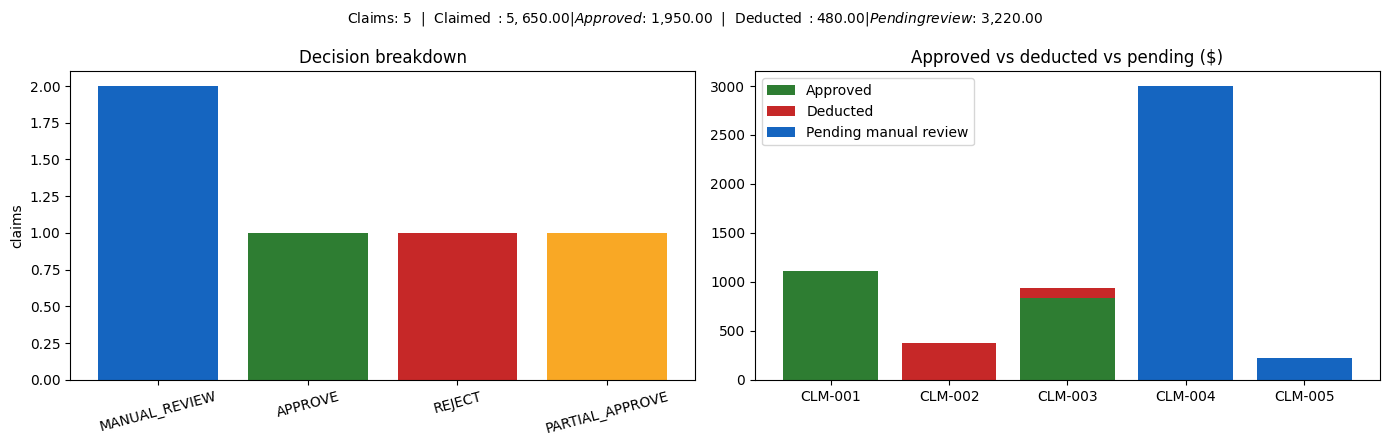

,claim_id,decision,approved_amount,deducted_amount,pending_review,confidence,missing_docs,policy_refs
0,CLM-001,APPROVE,1110.0,0.0,0.0,0.95,[],"[POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01..."
1,CLM-002,REJECT,0.0,380.0,0.0,0.97,[],[POL-CAT-02]
2,CLM-003,PARTIAL_APPROVE,840.0,100.0,0.0,0.92,[],"[POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01..."
3,CLM-004,MANUAL_REVIEW,0.0,0.0,3000.0,0.90,[Itemized lodging receipt ($600.00)],"[POL-AIR-01, POL-APR-03, POL-CAT-01, POL-PD-02..."
4,CLM-005,MANUAL_REVIEW,0.0,0.0,220.0,0.90,[Itemized meals receipt ($220.00)],"[POL-APR-01, POL-CAT-01, POL-PD-01, POL-RCT-01..."


Dropdown(description='Claim:', options=('CLM-001', 'CLM-002', 'CLM-003', 'CLM-004', 'CLM-005'), value='CLM-001…

Output()

In [10]:
"""Dashboard: KPIs, decision breakdown, approved vs deducted vs pending per claim; saves 'UI SS_1.png'."""
df = pd.DataFrame(RESULTS)
df["claimed"] = df["claim_id"].map(lambda c: sum(i["amount"] for i in CLAIMS[c]["items"]))
df["pending_review"] = (df["claimed"] - df["approved_amount"] - df["deducted_amount"]).round(2)
kpi = {"Claims": len(df), "Claimed $": df["claimed"].sum(), "Approved $": df["approved_amount"].sum(),
       "Deducted $": df["deducted_amount"].sum(), "Pending review $": df["pending_review"].sum()}

colors = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825", "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
counts = df["decision"].value_counts()
ax[0].bar(counts.index, counts.values, color=[colors[d] for d in counts.index])
ax[0].set_title("Decision breakdown"); ax[0].set_ylabel("claims"); ax[0].tick_params(axis="x", rotation=15)
ax[1].bar(df["claim_id"], df["approved_amount"], label="Approved", color="#2e7d32")
ax[1].bar(df["claim_id"], df["deducted_amount"], bottom=df["approved_amount"], label="Deducted", color="#c62828")
ax[1].bar(df["claim_id"], df["pending_review"], bottom=df["approved_amount"] + df["deducted_amount"], label="Pending manual review", color="#1565c0")
ax[1].set_title("Approved vs deducted vs pending ($)"); ax[1].legend()
fig.suptitle("  |  ".join(f"{k}: {v:,.2f}" if "$" in k else f"{k}: {v}" for k, v in kpi.items()), fontsize=10)
plt.tight_layout(); fig.savefig("UI SS_1.png", dpi=120); plt.show()
display(df[["claim_id", "decision", "approved_amount", "deducted_amount", "pending_review", "confidence", "missing_docs", "policy_refs"]])

try:                                              # interactive audit-trail viewer
    import ipywidgets as w
    dd, out = w.Dropdown(options=SAMPLE_IDS, description="Claim:"), w.Output()
    def _show(_=None):
        """Re-render the audit trail for the selected claim."""
        with out:
            clear_output(); print_audit(dd.value)
    dd.observe(_show, "value"); display(dd, out); _show()
except ImportError:
    print_audit(SAMPLE_IDS[0])

In [11]:
"""Try your own claim: edit this dict and re-run the cell (it is NOT part of the final results)."""
CUSTOM_CLAIM = {"claim_id": "CUSTOM-001", "employee": "F. Example", "purpose": "Customer workshop (business)",
                "trip_start": "2026-06-01", "trip_end": "2026-06-02", "submitted": "2026-06-05",
                "items": [item("airfare", "Round-trip economy airfare", 380, True),
                          item("ground_transport", "Taxi and rideshare", 120, True, units=2),
                          item("alcohol", "Dinner wine", 40, True)]}
CLAIMS[CUSTOM_CLAIM["claim_id"]] = CUSTOM_CLAIM
RUNS[CUSTOM_CLAIM["claim_id"]] = process_claim(CUSTOM_CLAIM["claim_id"])
print_audit(CUSTOM_CLAIM["claim_id"])
CLAIMS.pop(CUSTOM_CLAIM["claim_id"]); RUNS.pop(CUSTOM_CLAIM["claim_id"])

CUSTOM-001  ->  PARTIAL_APPROVE   approved=$480.00  deducted=$60.00  confidence=0.92  [offline-scripted-planner]
  why     : Ineligible items (alcohol, $40.00) are not reimbursable under POL-CAT-02. ground_transport $120.00 exceeds the cap of $100.00 (2 day(s)); $20.00 over the POL-PD-03 limit. Approved $480.00, deducted $60.00; remaining items are compliant and the total is in the auto tier.
  refs    : POL-AIR-01, POL-APR-01, POL-CAT-01, POL-CAT-02, POL-PD-03 | missing docs: -
  tool    : lookup_policy        (harness)
  tool    : check_consistency    (scripted)
  tool    : check_eligibility    (scripted)
  tool    : check_receipts       (scripted)
  tool    : check_per_diem       (scripted)
  tool    : check_airfare_class  (scripted)
  tool    : check_timeliness     (scripted)
  tool    : check_approval_tier  (scripted)
  tool    : detect_duplicates    (scripted)
  tool    : validate_output      (harness)



{'result': {'claim_id': 'CUSTOM-001',
  'decision': 'PARTIAL_APPROVE',
  'approved_amount': 480.0,
  'deducted_amount': 60.0,
  'missing_docs': [],
  'policy_refs': ['POL-AIR-01',
   'POL-APR-01',
   'POL-CAT-01',
   'POL-CAT-02',
   'POL-PD-03'],
  'confidence': 0.92,
  'explanation': 'Ineligible items (alcohol, $40.00) are not reimbursable under POL-CAT-02. ground_transport $120.00 exceeds the cap of $100.00 (2 day(s)); $20.00 over the POL-PD-03 limit. Approved $480.00, deducted $60.00; remaining items are compliant and the total is in the auto tier.',
  'tools_used': ['lookup_policy',
   'check_consistency',
   'check_eligibility',
   'check_receipts',
   'check_per_diem',
   'check_airfare_class',
   'check_timeliness',
   'check_approval_tier',
   'detect_duplicates',
   'validate_output']},
 'trace': [{'tool': 'lookup_policy',
   'source': 'harness',
   'args': {'query': 'airfare ground transport alcohol receipt approval threshold'},
   'output': {'rules': [{'id': 'POL-CAT-01',
 

# Design Notes & Reasoning

**Approach**
- *LLM plans, code decides.* The LLM chooses which tools to call and writes the explanation; decision, amounts and refs come from a deterministic rule engine. Money logic never depends on LLM arithmetic.
- *Grounding.* Policy is retrieved (keyword scoring) per claim and injected into the prompt; every output cites `POL-*` ids.
- *Reliability layers.* (1) harness forces mandatory tools the LLM skipped, (2) rules override a disagreeing LLM and lower confidence, (3) `validate_output` checks schema/sanity and falls back to `MANUAL_REVIEW`, (4) any LLM error falls back to the offline planner.
- *No key needed.* Offline mode runs identical tools so reviewers can run the notebook anywhere.

**Why Manual Review (per claim)**
- CLM-004: three independent triggers: business-class fare (POL-AIR-01, pre-approval may exist), missing lodging receipt (POL-RCT-02), reimbursable total $3,000 > $2,000 (POL-APR-03).
- CLM-005: no receipt for a $220 item (POL-RCT-02) and a group meal for 4 where policy does not say if the $75 cap is per person or per claim, so the agent will not force a $145 deduction.
- Approved and deducted are both `0` for manual-review claims except definite POL-CAT-02 deductions; nothing is paid before a human decides.

**Trade-offs**
- Keyword retrieval instead of a vector DB: the policy is 12 short rules; embeddings would be over-engineering.
- Deterministic final decision instead of trusting the LLM: slightly less "agentic", far more auditable.
- Confidence is a transparent heuristic (policy-mandated routing 0.90, ambiguity-only 0.70, clean decisions 0.92-0.97, minus 0.15 if the LLM disagreed), not a calibrated probability.

**What I would improve next**
- Parse free-text receipts/PDFs (OCR + LLM extraction) and verify receipt amounts against claim lines.
- Per-person meal caps and multi-day itemisation (dates per line) instead of even spreading over `units`.
- Pre-approval lookup tool for premium airfare; employee/grade-specific limits; currency conversion.
- Evaluation set of edge cases, LangGraph/MCP tool servers, and a Streamlit/Gradio UI.

# Assumptions & Limitations
- Currency USD; `units` (nights/days) and `attendees` are read from the claim descriptions in Appendix B.
- Per-diem caps are applied to the line total: `cap = rate x units` (spending assumed evenly distributed).
- Expense date = trip end date for the 30-day window.
- Approval tier is evaluated on the reimbursable total after per-diem and ineligible deductions, before the final decision (as per policy).
- Unknown categories are not auto-rejected; they go to Manual Review.
- Duplicate detection only compares claims inside this notebook / `HISTORY`.
- Groq model name may change; set `GROQ_MODEL` if the default is retired.

## Final structured results
One object per provided claim with exactly the required fields.

In [12]:
"""FINAL CELL: print the JSON array of results for all provided claims."""
print(json.dumps(RESULTS, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02"
    ],
    "confidence": 0.95,
    "explanation": "All items eligible, receipts present, within per-diem caps; reimbursable total $1110.00 is in the manager tier (POL-APR-02).",
    "tools_used": [
      "lookup_policy",
      "check_consistency",
      "check_eligibility",
      "check_receipts",
      "check_per_diem",
      "check_airfare_class",
      "check_timeliness",
      "check_approval_tier",
      "detect_duplicates",
      "validate_output"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-02"
    ],
    "confidence": 0.97,
    "explanation": "Ineligible items (spa, minibar, $380.00)